# Charm Production Cross-Section Ratio: $\sigma_{\mathrm{charm}} / \sigma_{\mathrm{CC}}$ vs $E_\nu$

This notebook loads and visualizes the inclusive charm production rate $\sigma_{\mathrm{charm}} / \sigma_{\mathrm{CC}}$ as a function of neutrino energy $E_\nu$, reproducing the comparison between:
- **SND@LHC MC Inclusive** ($\nu_\mu + \bar{\nu}_\mu$)
- **Historical Emulsion Measurements**: **CHORUS** (2011, $\nu_\mu$) and **E531** (1988, $\nu_\mu$)
- **LHAPDF nCTEQ15 Theoretical Predictions**: Evaluated for a nuclear emulsion target ($\langle Z/A \rangle \approx 0.467$)
- **Cumulative $1\sigma$ Uncertainty Belts**:
  - **Base Kinematics $1\sigma$**: Charm pole mass $m_c = 1.43 \pm 0.10\ \mathrm{GeV}$ & CKM $|V_{cd}| = 0.221 \pm 0.004$
  - **LHAPDF nCTEQ15 $1\sigma$**: Nuclear PDF eigenvector variations & QCD evolution

Inputs can be loaded either directly from the ROOT results file (`/eos/user/i/idioniso/snd-numu-charm/plots/charm_diagnostic_results.root`) via `ddfUtils.root.converters.to_numpy` or from the standalone precalculated LHAPDF prediction CSV files (`/eos/user/i/idioniso/snd-numu-charm/data/predictions/`).

In [2]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplhep as hep
import ROOT

ROOT.gROOT.SetBatch(True)
ROOT.gStyle.SetOptStat(0)
ROOT.gStyle.SetOptTitle(0)

import ddfUtils.root as dur
import ddfUtils.mpl_styling as dms
import ddfUtils.stats as dstats

print("Environment initialized: ROOT, mplhep, and ddfUtils ready.")

Environment initialized: ROOT, mplhep, and ddfUtils ready.


In [3]:
# -------------------------------------------------------------------------
# File Paths Configuration
# -------------------------------------------------------------------------
ROOT_CANDIDATES = [
    "/eos/user/i/idioniso/snd-numu-charm/plots/charm_diagnostic_results.root",
    "../plots/charm_diagnostic_results.root",
    "plots/charm_diagnostic_results.root",
    "charm_diagnostic_results.root",
]

PRED_DIR_CANDIDATES = [
    "/eos/user/i/idioniso/snd-numu-charm/data/predictions",
    "../scripts/diagnostics/predictions",
    "scripts/diagnostics/predictions",
    "/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions",
]

MEAS_DIR_CANDIDATES = [
    "../scripts/diagnostics/measurements",
    "scripts/diagnostics/measurements",
    "/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/measurements",
]

root_path = next((p for p in ROOT_CANDIDATES if os.path.exists(p)), None)
pred_dir = next((p for p in PRED_DIR_CANDIDATES if os.path.exists(p)), None)
meas_dir = next((p for p in MEAS_DIR_CANDIDATES if os.path.exists(p)), None)

print(f"ROOT file path:        {root_path}")
print(f"Predictions directory: {pred_dir}")
print(f"Measurements directory: {meas_dir}")

ROOT file path:        /eos/user/i/idioniso/snd-numu-charm/plots/charm_diagnostic_results.root
Predictions directory: /eos/user/i/idioniso/snd-numu-charm/data/predictions
Measurements directory: ../scripts/diagnostics/measurements


In [ ]:
# -------------------------------------------------------------------------
# Method 1: Load Data from ROOT via ddfUtils (dur.converters.to_numpy)
# -------------------------------------------------------------------------
def load_charm_rate_from_root(filepath: str, option: str = "inclusive", target: str = "tungsten"):
    f = ROOT.TFile.Open(filepath)
    if not f or f.IsZombie():
        raise FileNotFoundError(f"Could not open ROOT file at {filepath}")
    
    summary = f.Get("Summary")
    if not summary:
        raise KeyError("Directory 'Summary' not found in ROOT file.")
    
    # 1. MC Inclusive data points (TGraphAsymmErrors)
    if option.lower() in ["nu", "neutrino"]:
        g_mc = summary.Get("g_charm_rate_mc_nu")
    elif option.lower() in ["antinu", "anti-nu", "antineutrino", "anti-neutrino"]:
        g_mc = summary.Get("g_charm_rate_mc_antinu")
    else:
        g_mc = summary.Get("g_charm_rate_mc")
    mc_x, mc_y, mc_exl, mc_exh, mc_eyl, mc_eyh = dur.converters.to_numpy(g_mc)
    
    # 2. CHORUS measurement (TGraphErrors)
    g_chorus = summary.Get("g_chorus_measurement")
    ch_res = dur.converters.to_numpy(g_chorus)
    if len(ch_res) == 4:
        ch_x, ch_y, ch_ex, ch_ey = ch_res
        ch_exl, ch_exh, ch_eyl, ch_eyh = ch_ex, ch_ex, ch_ey, ch_ey
    else:
        ch_x, ch_y, ch_exl, ch_exh, ch_eyl, ch_eyh = ch_res
        
    # 3. E531 measurement (TGraphAsymmErrors)
    g_e531 = summary.Get("g_e531_measurement")
    e5_x, e5_y, e5_exl, e5_exh, e5_eyl, e5_eyh = dur.converters.to_numpy(g_e531)
    
    # 4. LHAPDF Prediction (TGraph)
    opt_key = "nu" if option.lower() in ["nu", "neutrino"] else ("antinu" if option.lower() in ["antinu", "anti-nu", "antineutrino", "anti-neutrino"] else "inclusive")
    
    # Load target-specific graphs (or fallback)
    tgt_suffix = f"_{target.lower()}"
    g_qcd = summary.Get(f"g_lhapdf_prediction_{opt_key}{tgt_suffix}") or summary.Get(f"g_lhapdf_prediction_{opt_key}")
    g_inner = summary.Get(f"g_lhapdf_{opt_key}_1sigma_inner_band{tgt_suffix}") or summary.Get(f"g_lhapdf_{opt_key}_1sigma_inner_band")
    g_outer = summary.Get(f"g_lhapdf_{opt_key}_1sigma_outer_band{tgt_suffix}") or summary.Get(f"g_lhapdf_{opt_key}_1sigma_outer_band")
    
    qcd_x, qcd_y = dur.converters.to_numpy(g_qcd)
    in_x, in_y, in_exl, in_exh, in_eyl, in_eyh = dur.converters.to_numpy(g_inner)
    out_x, out_y, out_exl, out_exh, out_eyl, out_eyh = dur.converters.to_numpy(g_outer)
    
    # Also check if emulsion graphs exist
    em_data = None
    g_qcd_em = summary.Get(f"g_lhapdf_prediction_{opt_key}_emulsion")
    if g_qcd_em:
        g_inner_em = summary.Get(f"g_lhapdf_{opt_key}_1sigma_inner_band_emulsion")
        g_outer_em = summary.Get(f"g_lhapdf_{opt_key}_1sigma_outer_band_emulsion")
        em_x, em_y = dur.converters.to_numpy(g_qcd_em)
        _, _, _, _, em_in_eyl, em_in_eyh = dur.converters.to_numpy(g_inner_em)
        _, _, _, _, em_out_eyl, em_out_eyh = dur.converters.to_numpy(g_outer_em)
        em_data = {
            "qcd": (em_x, em_y),
            "inner_band": (em_x, em_y, em_in_eyl, em_in_eyh),
            "outer_band": (em_x, em_y, em_out_eyl, em_out_eyh),
        }
    
    res = {
        "mc": (mc_x, mc_y, mc_exl, mc_exh, mc_eyl, mc_eyh),
        "chorus": (ch_x, ch_y, ch_exl, ch_exh, ch_eyl, ch_eyh),
        "e531": (e5_x, e5_y, e5_exl, e5_exh, e5_eyl, e5_eyh),
        "qcd": (qcd_x, qcd_y),
        "inner_band": (in_x, in_y, in_eyl, in_eyh),
        "outer_band": (out_x, out_y, out_eyl, out_eyh),
    }
    if em_data:
        res["emulsion"] = em_data
    return res


Extracted 9 MC points, 6 CHORUS points, 4 E531 points from ROOT.


In [ ]:
def load_charm_rate_from_csv(pred_directory: str, meas_directory: str, option: str = "inclusive", target: str = "tungsten"):
    # Map option aliases to corresponding prediction files and measurement channels
    option_map = {
        "inclusive": {
            "pred_file": "inclusive_numu_antinumu_charm_cross_section_ratio_prediction_lhapdf.csv",
            "meas_channel": "inclusive"
        },
        "nu": {
            "pred_file": "numuCC_charm_cross_section_ratio_prediction_lhapdf.csv",
            "meas_channel": "inclusive"  # CHORUS/E531 are neutrino-mode inclusive measurements
        },
        "anti-nu": {
            "pred_file": "antinumuCC_charm_cross_section_ratio_prediction_lhapdf.csv",
            "meas_channel": "anti_nu"
        }
    }
    
    cfg = option_map.get(option)
    if not cfg:
        raise ValueError(f"Unknown option '{option}'. Choose from: {list(option_map.keys())}")
    
    # 1. Load LHAPDF theory prediction
    pred_csv = os.path.join(pred_directory, cfg["pred_file"])
    if not os.path.exists(pred_csv):
        raise FileNotFoundError(f"Prediction file not found: {pred_csv}")
        
    df_pred = pd.read_csv(pred_csv)
    
    qcd_x = df_pred["E_nu_GeV"].to_numpy()
    
    # Resolve target prefix (tungsten vs emulsion)
    pref = f"{target.lower()}_" if f"{target.lower()}_ratio_central" in df_pred.columns else ""
    cen_col = f"{pref}ratio_central" if f"{pref}ratio_central" in df_pred.columns else "ratio_central"
    b_lo_col = f"{pref}base_unc_low" if f"{pref}base_unc_low" in df_pred.columns else "base_unc_low"
    b_hi_col = f"{pref}base_unc_high" if f"{pref}base_unc_high" in df_pred.columns else "base_unc_high"
    t_lo_col = f"{pref}total_unc_low" if f"{pref}total_unc_low" in df_pred.columns else "total_unc_low"
    t_hi_col = f"{pref}total_unc_high" if f"{pref}total_unc_high" in df_pred.columns else "total_unc_high"
    
    qcd_y = df_pred[cen_col].to_numpy()
    in_eyl = df_pred[b_lo_col].to_numpy()
    in_eyh = df_pred[b_hi_col].to_numpy()
    out_eyl = df_pred[t_lo_col].to_numpy()
    out_eyh = df_pred[t_hi_col].to_numpy()
    
    # Check if emulsion columns also exist
    em_data = None
    if "emulsion_ratio_central" in df_pred.columns:
        em_data = {
            "qcd": (qcd_x, df_pred["emulsion_ratio_central"].to_numpy()),
            "inner_band": (qcd_x, df_pred["emulsion_ratio_central"].to_numpy(), df_pred["emulsion_base_unc_low"].to_numpy(), df_pred["emulsion_base_unc_high"].to_numpy()),
            "outer_band": (qcd_x, df_pred["emulsion_ratio_central"].to_numpy(), df_pred["emulsion_total_unc_low"].to_numpy(), df_pred["emulsion_total_unc_high"].to_numpy()),
        }
    
    # 2. Load historical benchmark measurements
    meas_csv = os.path.join(meas_directory, "neutrino_charm_cross_section_ratio_vs_enu.csv")
    df_meas = pd.read_csv(meas_csv, comment="#")
    
    target_channel = cfg["meas_channel"]
    ch_mask = (df_meas["experiment"].str.strip() == "CHORUS")
    e5_mask = (df_meas["experiment"].str.strip() == "E531")
    
    if "channel" in df_meas.columns:
        channel_col = df_meas["channel"].str.strip()
        ch_sub = df_meas[ch_mask & (channel_col == target_channel)]
        e5_sub = df_meas[e5_mask & (channel_col == target_channel)]
        if ch_sub.empty:
            ch_sub = df_meas[ch_mask & (channel_col == "inclusive")]
        if e5_sub.empty:
            e5_sub = df_meas[e5_mask & (channel_col == "inclusive")]
    else:
        ch_sub = df_meas[ch_mask]
        e5_sub = df_meas[e5_mask]
    
    res = {
        "qcd": (qcd_x, qcd_y),
        "inner_band": (qcd_x, qcd_y, in_eyl, in_eyh),
        "outer_band": (qcd_x, qcd_y, out_eyl, out_eyh),
        "chorus": (
            ch_sub["E_nu_GeV"].to_numpy(), ch_sub["ratio"].to_numpy(),
            ch_sub["dx_low"].to_numpy(), ch_sub["dx_high"].to_numpy(),
            ch_sub["dy_low"].to_numpy(), ch_sub["dy_high"].to_numpy()
        ),
        "e531": (
            e5_sub["E_nu_GeV"].to_numpy(), e5_sub["ratio"].to_numpy(),
            e5_sub["dx_low"].to_numpy(), e5_sub["dx_high"].to_numpy(),
            e5_sub["dy_low"].to_numpy(), e5_sub["dy_high"].to_numpy()
        ),
    }
    if em_data:
        res["emulsion"] = em_data
    return res


Loaded 800 theory prediction points from CSV.


In [27]:
data_root = load_charm_rate_from_root(root_path, option="nu")
print(f"Extracted {len(data_root['mc'][0])} MC points, {len(data_root['chorus'][0])} CHORUS points, {len(data_root['e531'][0])} E531 points from ROOT.")


data_csv = load_charm_rate_from_csv(pred_dir, meas_dir, option="nu")
print(f"Loaded {len(data_csv['qcd'][0])} theory prediction points from CSV.")

Extracted 9 MC points, 6 CHORUS points, 4 E531 points from ROOT.
Loaded 800 theory prediction points from CSV.


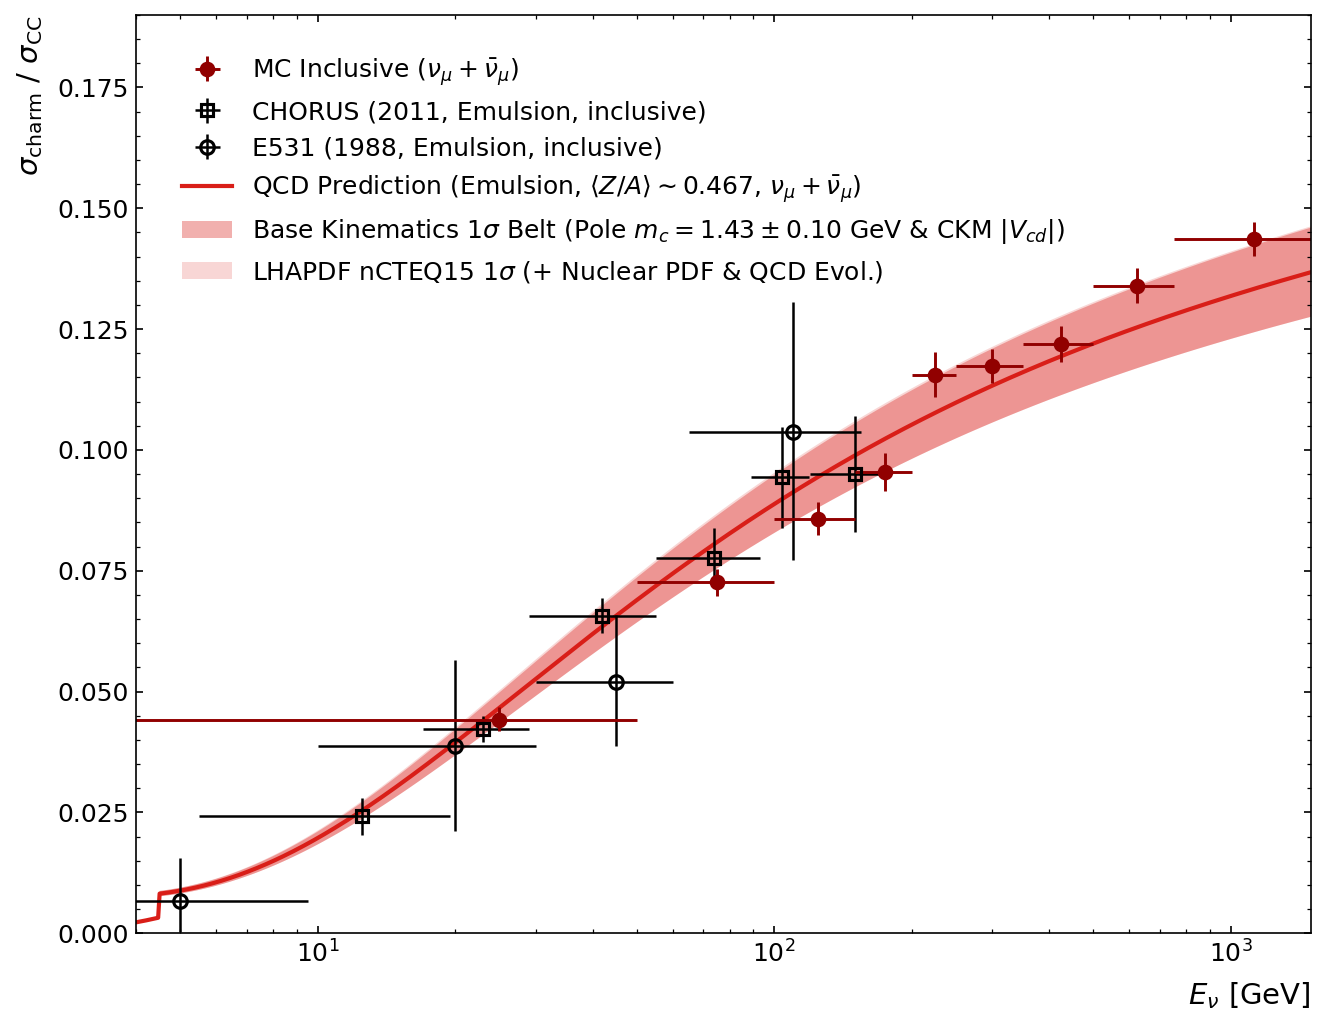

In [ ]:
# -------------------------------------------------------------------------
# Publication-Quality Reproduction Plot (Matplotlib + HEP Styling)
# -------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
})

fig, ax = plt.subplots(figsize=(9, 7), dpi=150)

# Use data from ROOT (or fallback to CSV)
data_source = data_root if "data_root" in locals() and data_root is not None else data_csv

mc_x, mc_y, mc_exl, mc_exh, mc_eyl, mc_eyh = data_source["mc"]
ch_x, ch_y, ch_exl, ch_exh, ch_eyl, ch_eyh = data_source["chorus"]
e5_x, e5_y, e5_exl, e5_exh, e5_eyl, e5_eyh = data_source["e531"]
qcd_x, qcd_y = data_source["qcd"]
in_x, in_y, in_eyl, in_eyh = data_source["inner_band"]
out_x, out_y, out_eyl, out_eyh = data_source["outer_band"]

col_red = "#d91e18"

# 1. Tungsten Target Uncertainty Bands (Solid transparent)
h_outer = ax.fill_between(
    out_x, out_y - out_eyl, out_y + out_eyh,
    color=col_red, alpha=0.18, edgecolor="none",
    label=r"LHAPDF nCTEQ15 $1\sigma$ ($^{184}\mathrm{W}$ target)"
)

h_inner = ax.fill_between(
    in_x, in_y - in_eyl, in_y + in_eyh,
    color=col_red, alpha=0.35, edgecolor="none",
    label=r"Base Kinematics $1\sigma$ Belt ($^{184}\mathrm{W}$, Pole $m_c = 1.43$ GeV)"
)

# 2. Central Prediction Curves (Tungsten solid)
(h_qcd,) = ax.plot(
    qcd_x, qcd_y,
    color=col_red, lw=2.0, linestyle="-",
    label=r"QCD Prediction ($^{184}\mathrm{W}$ target, solid)"
)

# Optional Emulsion Target Curves (Hatched + Dashed)
legend_handles = []
if "emulsion" in data_source:
    em = data_source["emulsion"]
    em_x, em_y = em["qcd"]
    _, _, em_in_eyl, em_in_eyh = em["inner_band"]
    _, _, em_out_eyl, em_out_eyh = em["outer_band"]
    (h_qcd_em,) = ax.plot(em_x, em_y, color=col_red, lw=1.8, linestyle="--", label=r"QCD Prediction (Emulsion, dashed)")
    h_inner_em = ax.fill_between(em_x, em_y - em_in_eyl, em_y + em_in_eyh, facecolor="none", edgecolor=col_red, hatch="//", linewidth=0.5, alpha=0.5, label=r"Base $1\sigma$ (Emulsion, //)")
    h_outer_em = ax.fill_between(em_x, em_y - em_out_eyl, em_y + em_out_eyh, facecolor="none", edgecolor=col_red, hatch="\\\\", linewidth=0.5, alpha=0.4, label=r"LHAPDF $1\sigma$ (Emulsion, \\\\)")

# 3. E531 Measurement (Black open circle)
h_e531 = ax.errorbar(
    e5_x, e5_y, xerr=[e5_exl, e5_exh], yerr=[e5_eyl, e5_eyh],
    fmt="o", color="black", mfc="none", mec="black", mew=1.5,
    markersize=6.5, elinewidth=1.2, capsize=0,
    label="E531 (1988, Emulsion, inclusive)"
)

# 4. CHORUS Measurement (Black open square)
h_chorus = ax.errorbar(
    ch_x, ch_y, xerr=[ch_exl, ch_exh], yerr=[ch_eyl, ch_eyh],
    fmt="s", color="black", mfc="none", mec="black", mew=1.5,
    markersize=6.0, elinewidth=1.2, capsize=0,
    label="CHORUS (2011, Emulsion, inclusive)"
)

# 5. MC Data Points (Red filled circles)
h_mc = ax.errorbar(
    mc_x, mc_y, xerr=[mc_exl, mc_exh], yerr=[mc_eyl, mc_eyh],
    fmt="o", color="#910000", mfc="#910000", mec="#910000", mew=1.5,
    markersize=6.0, elinewidth=1.4, capsize=0,
    label=r"MC ($\nu_\mu$ CC, Tungsten)"
)

# Axes, Grid & Limits
ax.set_xscale("log")
ax.set_xlim(4, 1500.0)
ax.set_ylim(0.0, 0.19)

ax.set_xlabel(r"$E_\nu\ [\mathrm{GeV}]$", fontsize=14, loc="right", labelpad=6)
ax.set_ylabel(r"$\sigma_{\mathrm{charm}}\ /\ \sigma_{\mathrm{CC}}$", fontsize=14, loc="top", labelpad=6)

legend_handles = [h_mc, h_chorus, h_e531, h_qcd, h_inner, h_outer]
if "emulsion" in data_source:
    legend_handles.extend([h_qcd_em, h_inner_em, h_outer_em])

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.02, 0.98),
    frameon=False,
    facecolor="white",
    edgecolor="black",
    framealpha=0.92,
    fontsize=10,
)

plt.tight_layout()
plt.show()


In [ ]:
# -------------------------------------------------------------------------
# Direct Inline Rendering of TCanvas from ROOT File
# -------------------------------------------------------------------------
from IPython.display import Image, display

f_root = ROOT.TFile.Open(root_path)
canv = f_root.Get("Canvases/c_charm_rate_vs_energy")
if canv:
    temp_canvas_path = "/tmp/c_charm_rate_vs_energy_inline.png"
    canv.SaveAs(temp_canvas_path)
    display(Image(filename=temp_canvas_path))
else:
    print("Canvas c_charm_rate_vs_energy not found in Canvases/")

In [ ]:
# -------------------------------------------------------------------------
# Multi-Beam Comparison Canvas (Inclusive vs Nu vs Anti-Nu)
# -------------------------------------------------------------------------
canv_comp = f_root.Get("Canvases/c_charm_rate_vs_energy_comparison")
if canv_comp:
    temp_comp_path = "/tmp/c_charm_rate_vs_energy_comp_inline.png"
    canv_comp.SaveAs(temp_comp_path)
    display(Image(filename=temp_comp_path))
else:
    print("Canvas c_charm_rate_vs_energy_comparison not found in Canvases/")